# The Jarzynski Equality

A system in a heat bath at temperature $T$ is driven by changing a parameter $\lambda$ from
$\lambda_0$ to $\lambda_1$ in a finite time $\tau$. The work $W$ differs from run to run, and the
second law only bounds its mean: $\langle W\rangle \ge \Delta F$. Jarzynski's equality holds
exactly at **any** driving speed:

$$\langle e^{-\beta W}\rangle = e^{-\beta\Delta F}, \qquad \beta = 1/k_BT .$$

So an equilibrium free-energy difference can be measured from fast, irreversible runs. The
catch is that the average is dominated by rare runs with $W < \Delta F$.

**Units:** $k_BT = \gamma = k = 1$, so $\beta = 1$ and the relaxation time is $\tau_r = \gamma/k = 1$.
Lengths are in $\sqrt{k_BT/k}$, energies in $k_BT$, times in $\tau_r$.

## Dragged Harmonic Trap

$H(x;\lambda) = \tfrac{k}{2}(x-\lambda)^2$, with the trap centre dragged at constant speed,
$\lambda(t) = vt$. The trap's shape never changes, so $\Delta F = 0$ and Jarzynski predicts
$\langle e^{-\beta W}\rangle = 1$ exactly.

**Physical picture.** An optical tweezer: a focused laser holds a ~1 μm bead in water like a
spring of stiffness $k$, centred on the focus $\lambda$. Moving the focus drags the bead through
the water. Viscous drag $\gamma$ makes it lag, and Brownian kicks make it jitter. The puller does
work $W = \int k(\lambda - x)\,d\lambda$ against the spring, all of which ends up as heat.

| unit | physical value |
|---|---|
| $\tau_r$ | ≈ 1 ms |
| $\sqrt{k_BT/k}$ | ≈ 20 nm |
| $k_BT$ | ≈ 4 × 10⁻²¹ J |

At this scale thermal kicks are as large as the work, so some runs have $W < 0$. These were
observed in this exact experiment by Wang *et al.*, PRL **89**, 050601 (2002).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Units: k_B T = gamma = k = 1, so beta = 1 and the trap relaxation time tau_r = gamma/k = 1.
kT, gamma, k = 1.0, 1.0, 1.0
beta = 1 / kT
tau_r = gamma / k

def H(x, lam):
    """Dragged harmonic trap: H(x; lam) = k/2 (x - lam)^2, centred at lam."""
    return 0.5 * k * (x - lam)**2

def force(x, lam):
    """-dH/dx, the force the trap exerts on the particle."""
    return -k * (x - lam)

def protocol(t, v):
    """Trap centre dragged at constant speed v, starting from lam(0) = 0."""
    return v * t

def sample_equilibrium(N, lam, rng):
    """N exact Boltzmann samples in the trap at lam: Gaussian with mean lam, variance kT/k."""
    return rng.normal(lam, np.sqrt(kT / k), size=N)

max |force - (-dH/dx)|      = 2.7e-10
Z(0) = 2.5066282746,  exact sqrt(2 pi kT/k) = 2.5066282746
Delta F(0 -> 5) by quadrature = -2.2e-16   (exact 0)
<x>   = +0.0010 +- 0.0010   (exact 0)
<x^2> = 1.0014 +- 0.0014   (exact kT/k = 1.0)


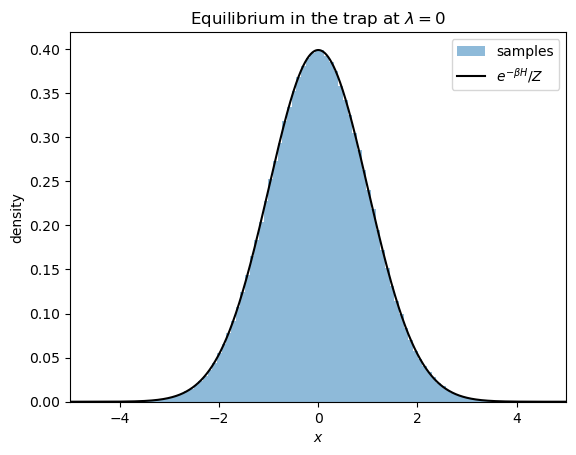

In [2]:
# CHECK: the trap, its force, and the equilibrium sampler all agree with each other.
rng = np.random.default_rng(0)
N = 10**6

# 1. force really is -dH/dx (central difference, error O(h^2), exact here up to roundoff)
x, lam, h = rng.normal(size=1000), 2.0, 1e-5
fd = -(H(x + h, lam) - H(x - h, lam)) / (2 * h)
print(f"max |force - (-dH/dx)|      = {np.max(np.abs(force(x, lam) - fd)):.1e}")

# 2. Z(lam) by quadrature is independent of lam, so Delta F = -kT ln(Z1/Z0) = 0 for dragging
xg = np.linspace(-20, 25, 20001)
Z = lambda lam: np.trapezoid(np.exp(-beta * H(xg, lam)), xg)
print(f"Z(0) = {Z(0):.10f},  exact sqrt(2 pi kT/k) = {np.sqrt(2*np.pi*kT/k):.10f}")
print(f"Delta F(0 -> 5) by quadrature = {-kT*np.log(Z(5)/Z(0)):.1e}   (exact 0)")

# 3. sampler: mean lam and variance kT/k (equipartition), within statistical error
xs = sample_equilibrium(N, 0.0, rng)
print(f"<x>   = {xs.mean():+.4f} +- {np.sqrt(kT/k/N):.4f}   (exact 0)")
print(f"<x^2> = {xs.var():.4f} +- {np.sqrt(2/N)*kT/k:.4f}   (exact kT/k = {kT/k})")

# 4. histogram of samples vs the Boltzmann density exp(-beta H)/Z
plt.hist(xs, bins=100, density=True, alpha=0.5, label="samples")
plt.plot(xg, np.exp(-beta * H(xg, 0.0)) / Z(0), "k", label=r"$e^{-\beta H}/Z$")
plt.xlim(-5, 5); plt.xlabel("$x$"); plt.ylabel("density"); plt.legend()
plt.title(r"Equilibrium in the trap at $\lambda = 0$")
plt.show()

**Plot:** $10^6$ beads sampled in the trap at $\lambda = 0$ match the Boltzmann density
$e^{-\beta H}/Z$, a Gaussian of width $\sqrt{k_BT/k}$. These are the equilibrium starting
positions for every run.

## Langevin Integrator

The bead has negligible inertia, so it follows overdamped Langevin dynamics,
$\gamma\dot x = -\partial_x H + \sqrt{2\gamma k_BT}\,\eta(t)$. We step all beads at once with
Euler–Maruyama:

$$x_{n+1} = x_n + \frac{F(x_n,\lambda_n)}{\gamma}\Delta t + \sqrt{\frac{2k_BT\,\Delta t}{\gamma}}\;\xi_n, \qquad \xi_n\sim\mathcal N(0,1).$$

Each step first moves the trap at fixed $x$ and adds $H(x,\lambda_{n+1}) - H(x,\lambda_n)$ to $W$,
then moves the bead at fixed trap (heat).

In [3]:
from types import SimpleNamespace

def run_protocol(x0, lam_of_t, tau, dt, rng, n_keep=20):
    """Euler-Maruyama for gamma dx/dt = F(x, lam(t)) + sqrt(2 gamma kT) eta, all beads at once.

    Each step: (1) move the trap at fixed x, adding the energy change to the work W;
               (2) move the beads at fixed trap (that energy change is heat).
    Returns times t, trap positions lam, ensemble mean and variance of x at each time,
    the full paths of the first n_keep beads, and the work W of every bead.
    """
    n_steps = round(tau / dt)
    assert np.isclose(n_steps * dt, tau), "tau must be a whole number of steps"
    t = np.arange(n_steps + 1) * dt
    lam = lam_of_t(t)
    kick = np.sqrt(2 * kT * dt / gamma)

    x, W = x0.copy(), np.zeros_like(x0)
    x_mean, x_var, paths = [x.mean()], [x.var()], [x[:n_keep].copy()]
    for n in range(n_steps):
        W += H(x, lam[n + 1]) - H(x, lam[n])                                   # work
        x += force(x, lam[n + 1]) / gamma * dt + kick * rng.normal(size=x.size)  # heat
        x_mean.append(x.mean()); x_var.append(x.var()); paths.append(x[:n_keep].copy())

    return SimpleNamespace(t=t, lam=lam, x_mean=np.array(x_mean), x_var=np.array(x_var),
                           paths=np.array(paths), W=W)

dt = 0.200:  <x^2> = 1.1121 +- 0.0014,  EM exact = 1.1111,  max|W| = 0e+00
dt = 0.100:  <x^2> = 1.0517 +- 0.0014,  EM exact = 1.0526,  max|W| = 0e+00
dt = 0.050:  <x^2> = 1.0278 +- 0.0014,  EM exact = 1.0256,  max|W| = 0e+00
dt = 0.025:  <x^2> = 1.0113 +- 0.0014,  EM exact = 1.0127,  max|W| = 0e+00


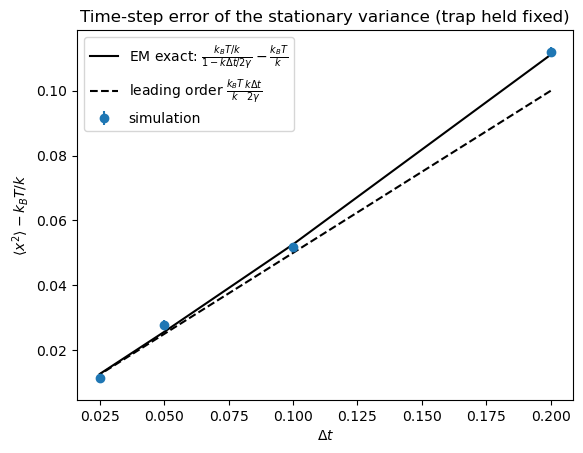

In [4]:
# CHECK: with the trap held still, an equilibrium start stays in equilibrium and no work is done.
# Euler-Maruyama's stationary variance for this trap is exactly (kT/k) / (1 - k dt / 2 gamma).
rng = np.random.default_rng(1)
N, tau = 10**6, 10 * tau_r
dts = np.array([0.2, 0.1, 0.05, 0.025])
var_exact = kT / k / (1 - k * dts / (2 * gamma))
err = np.sqrt(2 / N) * kT / k                    # statistical error of a variance from N samples

var_sim = []
for dt, ve in zip(dts, var_exact):
    r = run_protocol(sample_equilibrium(N, 0.0, rng), lambda t: 0 * t, tau, dt, rng)
    var_sim.append(r.x_var[-1])
    print(f"dt = {dt:5.3f}:  <x^2> = {r.x_var[-1]:.4f} +- {err:.4f},  EM exact = {ve:.4f},  "
          f"max|W| = {np.abs(r.W).max():.0e}")

plt.errorbar(dts, np.array(var_sim) - kT / k, yerr=err, fmt="o", label="simulation")
plt.plot(dts, var_exact - kT / k, "k-", label=r"EM exact: $\frac{k_BT/k}{1 - k\Delta t/2\gamma} - \frac{k_BT}{k}$")
plt.plot(dts, kT / k * k * dts / (2 * gamma), "k--", label=r"leading order $\frac{k_BT}{k}\frac{k\Delta t}{2\gamma}$")
plt.xlabel(r"$\Delta t$"); plt.ylabel(r"$\langle x^2\rangle - k_BT/k$"); plt.legend()
plt.title("Time-step error of the stationary variance (trap held fixed)")
plt.show()

**Plot:** with the trap held still, the spread of the beads should stay at $k_BT/k$.
The x-axis is the time step $\Delta t$. The y-axis is the excess spread
$\langle x^2\rangle - k_BT/k$. The simulation follows the exact Euler–Maruyama result
$\frac{k_BT/k}{1-k\Delta t/2\gamma}$, so the only error is linear in $\Delta t$. We use
$\Delta t = 0.01$, which gives about a 0.5% error, and $W = 0$ exactly.

v = 0.5:  final lag = -0.496 +- 0.003   analytic = -0.497   with EM step = -0.492   max|var(x) - kT/k| = 0.020
v = 1.0:  final lag = -0.982 +- 0.003   analytic = -0.993   with EM step = -0.983   max|var(x) - kT/k| = 0.016
v = 2.0:  final lag = -1.966 +- 0.003   analytic = -1.987   with EM step = -1.967   max|var(x) - kT/k| = 0.015


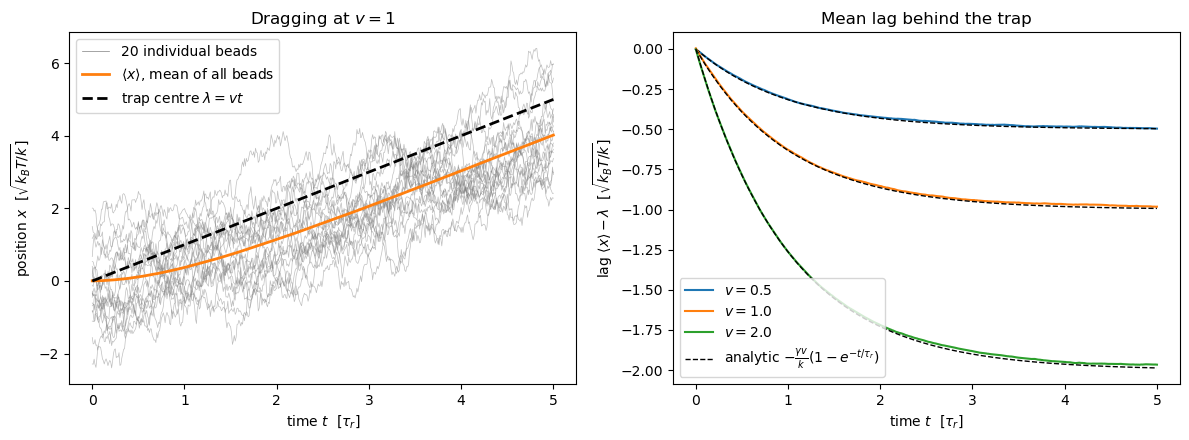

In [5]:
# Drag the trap at constant speed v and watch the beads lag behind it.
# Analytic mean lag (continuous time): <x> - lam = -(gamma v / k) (1 - exp(-t / tau_r)).
# Euler-Maruyama shrinks the steady lag by exactly (1 - k dt / gamma), a 1% effect at dt = 0.01.
rng = np.random.default_rng(2)
N, tau, dt = 10**5, 5 * tau_r, 0.01
lag_exact = lambda t, v: -(gamma * v / k) * (1 - np.exp(-t / tau_r))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for v, color in zip([0.5, 1.0, 2.0], ["C0", "C1", "C2"]):
    r = run_protocol(sample_equilibrium(N, 0.0, rng), lambda t: protocol(t, v), tau, dt, rng)
    lag, lag_th = r.x_mean[-1] - r.lam[-1], lag_exact(tau, v)
    print(f"v = {v}:  final lag = {lag:+.3f} +- {np.sqrt(kT / k / N):.3f}   analytic = {lag_th:+.3f}"
          f"   with EM step = {lag_th * (1 - k * dt / gamma):+.3f}   max|var(x) - kT/k| = {np.abs(r.x_var - kT / k).max():.3f}")
    ax2.plot(r.t, r.x_mean - r.lam, color=color, label=f"$v = {v}$")
    ax2.plot(r.t, lag_exact(r.t, v), "k--", lw=1)
    if v == 1.0:
        ax1.plot(r.t, r.paths, color="gray", lw=0.5, alpha=0.5)
        ax1.plot([], [], color="gray", lw=0.5, label="20 individual beads")
        ax1.plot(r.t, r.x_mean, color=color, lw=2, label=r"$\langle x\rangle$, mean of all beads")
        ax1.plot(r.t, r.lam, "k--", lw=2, label=r"trap centre $\lambda = vt$")

ax1.set(xlabel=r"time $t$  [$\tau_r$]", ylabel=r"position $x$  [$\sqrt{k_BT/k}$]", title="Dragging at $v = 1$")
ax1.legend()
ax2.plot([], [], "k--", lw=1, label=r"analytic $-\frac{\gamma v}{k}(1 - e^{-t/\tau_r})$")
ax2.set(xlabel=r"time $t$  [$\tau_r$]", ylabel=r"lag $\langle x\rangle - \lambda$  [$\sqrt{k_BT/k}$]",
        title="Mean lag behind the trap")
ax2.legend()
plt.tight_layout()
plt.show()

**Plot:**
- **Left:** bead positions vs time at $v = 1$. Individual beads are gray, their mean
  $\langle x\rangle$ is orange, and the trap centre is dashed.
- **Right:** the mean lag $\langle x\rangle - \lambda$ for three speeds, against the analytic
  $-\frac{\gamma v}{k}(1-e^{-t/\tau_r})$.

The beads fall behind until the spring force $k\cdot\text{lag}$ balances the drag $\gamma v$, so
the lag is $\gamma v/k$. From then on they move parallel to the trap in a steady state that is
not equilibrium: it is the Boltzmann Gaussian, shifted behind the trap. This lag is the
dissipation. The power is $k\cdot\text{lag}\cdot v = \gamma v^2$, so $\langle W\rangle > 0 = \Delta F$.
The remaining ~1% gap is the $\Delta t$ error.

## Work and the Jarzynski Equality

Integrating the power gives
$\langle W\rangle = \gamma v^2\left[\tau - \tau_r(1-e^{-\tau/\tau_r})\right] > 0$. Yet Jarzynski
requires $\langle e^{-\beta W}\rangle = 1$. The two are reconciled by fluctuations: $W$ is
Gaussian here, and $\langle e^{-\beta W}\rangle = e^{-\beta\langle W\rangle + \beta^2\sigma_W^2/2} = 1$
requires

$$\sigma_W^2 = 2k_BT\,\langle W\rangle .$$

The more work is dissipated on average, the wider its spread, so some beads end with
$W < 0$.

tau =  0.1:  <W> = 4.351 +- 0.009  (analytic 4.354, off by -0.3 err)   sigma_W^2 / 2kT<W> = 0.999 +- 0.004   Delta F_J = +0.059 +- 0.070
tau =  0.3:  <W> = 4.104 +- 0.009  (analytic 4.082, off by +2.4 err)   sigma_W^2 / 2kT<W> = 0.999 +- 0.004   Delta F_J = +0.076 +- 0.052
tau =  1.0:  <W> = 3.303 +- 0.008  (analytic 3.311, off by -1.0 err)   sigma_W^2 / 2kT<W> = 1.006 +- 0.004   Delta F_J = -0.019 +- 0.048
tau =  3.0:  <W> = 2.032 +- 0.006  (analytic 2.050, off by -2.8 err)   sigma_W^2 / 2kT<W> = 1.011 +- 0.005   Delta F_J = -0.023 +- 0.019
tau = 10.0:  <W> = 0.809 +- 0.004  (analytic 0.810, off by -0.3 err)   sigma_W^2 / 2kT<W> = 0.997 +- 0.004   Delta F_J = +0.004 +- 0.006
tau = 30.0:  <W> = 0.289 +- 0.002  (analytic 0.290, off by -0.3 err)   sigma_W^2 / 2kT<W> = 0.998 +- 0.004   Delta F_J = +0.001 +- 0.003


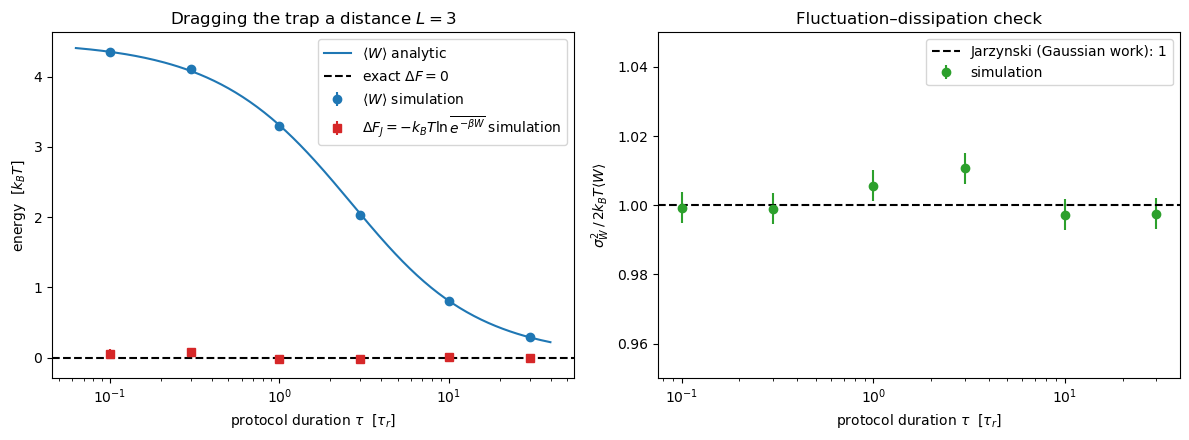

In [6]:
# Work over a range of durations tau, always dragging the trap the same distance L (so v = L / tau).
# Analytic (continuous time): <W> = gamma v^2 [tau - tau_r (1 - e^{-tau/tau_r})],  sigma_W^2 = 2 kT <W>,  Delta F = 0.
rng = np.random.default_rng(3)
N, dt, L = 10**5, 0.01, 3.0
taus = np.array([0.1, 0.3, 1, 3, 10, 30]) * tau_r
W_mean_exact = lambda tau: gamma * (L / tau)**2 * (tau - tau_r * (1 - np.exp(-tau / tau_r)))

W_mean, W_err, ratio, ratio_err, dF_J, dF_J_err = [np.zeros(len(taus)) for _ in range(6)]
for i, tau in enumerate(taus):
    W = run_protocol(sample_equilibrium(N, 0.0, rng), lambda t: protocol(t, L / tau), tau, dt, rng).W
    boltz = np.exp(-beta * W)
    W_mean[i], W_err[i] = W.mean(), W.std() / np.sqrt(N)
    ratio[i] = W.var() / (2 * kT * W.mean());   ratio_err[i] = ratio[i] * np.sqrt(2 / N)
    dF_J[i] = -kT * np.log(boltz.mean());       dF_J_err[i] = kT * boltz.std() / (boltz.mean() * np.sqrt(N))
    print(f"tau = {tau:4.1f}:  <W> = {W_mean[i]:.3f} +- {W_err[i]:.3f}  (analytic {W_mean_exact(tau):.3f},"
          f" off by {(W_mean[i] - W_mean_exact(tau)) / W_err[i]:+.1f} err)   sigma_W^2 / 2kT<W> = {ratio[i]:.3f} +- {ratio_err[i]:.3f}"
          f"   Delta F_J = {dF_J[i]:+.3f} +- {dF_J_err[i]:.3f}")

tt = np.logspace(-1.2, 1.6, 200) * tau_r
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(tt, W_mean_exact(tt), "C0-", label=r"$\langle W\rangle$ analytic")
ax1.errorbar(taus, W_mean, yerr=W_err, fmt="C0o", label=r"$\langle W\rangle$ simulation")
ax1.errorbar(taus, dF_J, yerr=dF_J_err, fmt="C3s", label=r"$\Delta F_J = -k_BT\ln\overline{e^{-\beta W}}$ simulation")
ax1.axhline(0, color="k", ls="--", label=r"exact $\Delta F = 0$")
ax1.set(xscale="log", xlabel=r"protocol duration $\tau$  [$\tau_r$]", ylabel=r"energy  [$k_BT$]",
        title=f"Dragging the trap a distance $L = {L:g}$")
ax1.legend()
ax2.errorbar(taus, ratio, yerr=ratio_err, fmt="C2o", label="simulation")
ax2.axhline(1, color="k", ls="--", label="Jarzynski (Gaussian work): 1")
ax2.set(xscale="log", xlabel=r"protocol duration $\tau$  [$\tau_r$]", ylabel=r"$\sigma_W^2 \,/\, 2k_BT\langle W\rangle$",
        title="Fluctuation–dissipation check", ylim=(0.95, 1.05))
ax2.legend()
plt.tight_layout()
plt.show()

**Plot:** the trap is dragged a fixed distance $L = 3$ over durations $\tau$ (log x-axis, fast on
the left, slow on the right), with $10^5$ beads per point.
- **Left:** $\langle W\rangle$ follows the analytic curve. It falls from $kL^2/2$ for a sudden jump
  toward 0 for a slow drag, always above $\Delta F$. The Jarzynski estimate
  $\Delta F_J = -k_BT\ln\overline{e^{-\beta W}}$ stays at $\Delta F = 0$ at every speed.
- **Right:** $\sigma_W^2/2k_BT\langle W\rangle = 1$ to within about 1%.

<e^(-beta W)>                       = 0.984 +- 0.023   (Jarzynski: exactly 1)
fraction of beads with W < 0        = 0.079   (analytic 0.078)
share of e^(-beta W) from W < 0     = 0.920   (analytic 0.922)
<W>                                 = 3.991 +- 0.003   (analytic 4.007; ~0.4% low is the dt = 0.01 step error)
weighted mean of W                  = -3.796   (analytic -<W> = -4.007)


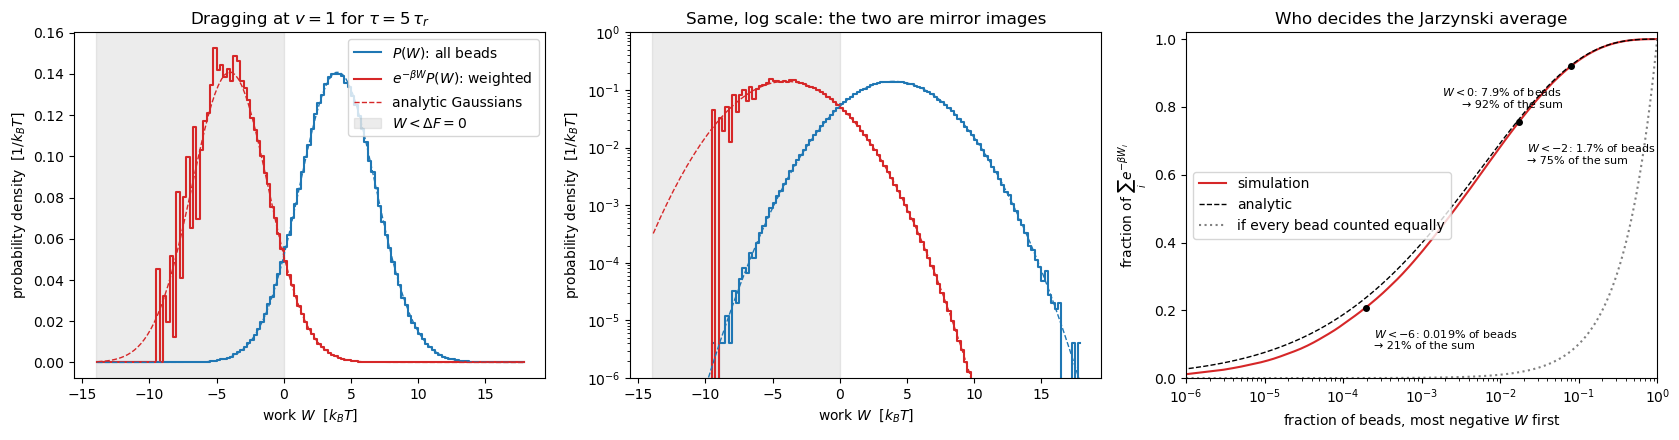

In [8]:
# Which beads matter for Jarzynski? Compare the work distribution P(W) with the e^{-beta W}-weighted one.
# Gaussian work with sigma_W^2 = 2 kT <W>  =>  the weighted distribution is P(W) mirrored, centred at -<W>.
from scipy.stats import norm
rng = np.random.default_rng(5)
N, dt, v, tau = 10**6, 0.01, 1.0, 5 * tau_r
W = run_protocol(sample_equilibrium(N, 0.0, rng), lambda t: protocol(t, v), tau, dt, rng, n_keep=0).W
boltz = np.exp(-beta * W)
W_avg = gamma * v**2 * (tau - tau_r * (1 - np.exp(-tau / tau_r)))   # analytic <W>
sig = np.sqrt(2 * kT * W_avg)                                        # analytic sigma_W

print(f"<e^(-beta W)>                       = {boltz.mean():.3f} +- {boltz.std() / np.sqrt(N):.3f}   (Jarzynski: exactly 1)")
print(f"fraction of beads with W < 0        = {np.mean(W < 0):.3f}   (analytic {norm.cdf(-W_avg / sig):.3f})")
print(f"share of e^(-beta W) from W < 0     = {boltz[W < 0].sum() / boltz.sum():.3f}   (analytic {norm.cdf(W_avg / sig):.3f})")
print(f"<W>                                 = {W.mean():.3f} +- {W.std() / np.sqrt(N):.3f}   (analytic {W_avg:.3f};"
      " ~0.4% low is the dt = 0.01 step error)")
print(f"weighted mean of W                  = {np.sum(W * boltz) / boltz.sum():+.3f}   (analytic -<W> = {-W_avg:+.3f})")

bins = np.linspace(-14, 18, 129)
Wc, dW = 0.5 * (bins[1:] + bins[:-1]), bins[1] - bins[0]
P = np.histogram(W, bins)[0] / (N * dW)                              # P(W)
P_w = np.histogram(W, bins, weights=boltz)[0] / (N * dW)             # e^{-beta W} P(W); its area is <e^{-beta W}> = 1

# Cumulative share: sort beads from most negative W up, and ask what fraction of the Jarzynski sum
# the first (most negative) n beads carry. Analytic: beads below w are Phi((w - <W>)/sig), their share Phi((w + <W>)/sig).
order = np.argsort(W)
frac_beads = np.arange(1, N + 1) / N
frac_sum = np.cumsum(boltz[order]) / boltz.sum()
w = np.linspace(-15, 15, 400)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, scale in zip(axes[:2], ["linear", "log"]):
    ax.step(Wc, P, where="mid", color="C0", label=r"$P(W)$: all beads")
    ax.step(Wc, P_w, where="mid", color="C3", label=r"$e^{-\beta W}P(W)$: weighted")
    ax.plot(Wc, norm.pdf(Wc, W_avg, sig), "C0--", lw=1)
    ax.plot(Wc, norm.pdf(Wc, -W_avg, sig), "C3--", lw=1, label="analytic Gaussians")
    ax.axvspan(bins[0], 0, color="gray", alpha=0.15, label=r"$W < \Delta F = 0$")
    ax.set(yscale=scale, xlabel=r"work $W$  [$k_BT$]", ylabel="probability density  [$1/k_BT$]")
axes[0].set_title(rf"Dragging at $v = {v:g}$ for $\tau = {tau:g}\,\tau_r$")
axes[0].legend()
axes[1].set(ylim=(1e-6, 1), title="Same, log scale: the two are mirror images")

ax = axes[2]
ax.plot(frac_beads, frac_sum, "C3", label="simulation")
ax.plot(norm.cdf((w - W_avg) / sig), norm.cdf((w + W_avg) / sig), "k--", lw=1, label="analytic")
ax.plot(frac_beads, frac_beads, ":", color="gray", label="if every bead counted equally")
for w0 in [0, -2, -6]:
    fb, fs = np.mean(W < w0), boltz[W < w0].sum() / boltz.sum()
    ax.plot(fb, fs, "ko", ms=4)
    right = fb > 0.05                                       # keep the label inside the axes
    ax.annotate(f"$W<{w0}$: {100 * fb:.2g}% of beads\n→ {100 * fs:.0f}% of the sum", (fb, fs), fontsize=8,
                xytext=(-6 if right else 6, -30), textcoords="offset points", ha="right" if right else "left")
ax.set(xscale="log", xlim=(1e-6, 1), ylim=(0, 1.02), xlabel="fraction of beads, most negative $W$ first",
       ylabel=r"fraction of $\sum_i e^{-\beta W_i}$", title="Who decides the Jarzynski average")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

**Plot:** $v = 1$, $\tau = 5\,\tau_r$, $10^6$ beads. A bead with $W = -4$ adds $e^{4}\approx 55$ to the
Jarzynski sum, while a typical bead with $W = +4$ adds $e^{-4}\approx 0.02$.
- **Left (linear) and middle (log):** blue is $P(W)$, where the beads land. Red is
  $e^{-\beta W}P(W)$, where the Jarzynski average comes from, and its area is
  $e^{-\beta\Delta F} = 1$. The weighting shifts the Gaussian by $\beta\sigma_W^2 = 2\langle W\rangle$,
  mirroring it about $W = \Delta F = 0$. The log scale shows the sparse tail: no bead reached
  past $W \approx -9$.
- **Right:** beads sorted from most negative $W$, with the fraction of beads included (x) against
  the fraction of $\sum e^{-\beta W}$ they carry (y). 8% of beads carry 92% of the sum, and
  0.02% carry 21%.

Missing that tail with too few runs makes $\Delta F_J$ too large, and faster pulls push it further
out of reach.